<a href="https://colab.research.google.com/github/er1cbrown/BiostatsPython/blob/main/Diabetic_Retinopathy_with_ResNet50%2C_Oversampling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# Removed %reload_ext autoreload and %autoreload 2 because 'imp' module is removed in Python 3.13
%matplotlib inline

In [10]:
# Removed %reload_ext autoreload and %autoreload 2 because 'imp' module is removed in Python 3.13
%matplotlib inline

# Diabetic Retinopathy

Diabetic retinopathy (DR), also known as diabetic eye disease, is a medical condition in which damage occurs to the retina due to diabetes mellitus. It is a leading cause of blindness. Diabetic retinopathy affects up to 80 percent of those who have had diabetes for 20 years or more. Diabetic retinopathy often has no early warning signs. **Retinal (fundus) photography with manual interpretation is a widely accepted screening tool for diabetic retinopathy**, with performance that can exceed that of in-person dilated eye examinations.

The below figure shows an example of a healthy patient and a patient with diabetic retinopathy as viewed by fundus photography ([source](https://www.biorxiv.org/content/biorxiv/early/2018/06/19/225508.full.pdf)):

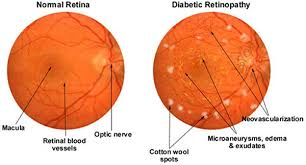

An automated tool for grading severity of diabetic retinopathy would be very useful for accerelating detection and treatment. Recently, there have been a number of attempts to utilize deep learning to diagnose DR and automatically grade diabetic retinopathy. This includes this [competition](https://kaggle.com/c/diabetic-retinopathy-detection) and [work by Google](https://ai.googleblog.com/2016/11/deep-learning-for-detection-of-diabetic.html). Even one deep-learning based system is [FDA approved](https://www.fda.gov/NewsEvents/Newsroom/PressAnnouncements/ucm604357.htm).

Clearly, this dataset and deep learning problem is quite well-characterized.

# A look at the data:

Data description from the competition:

>You are provided with a large set of high-resolution retina images taken under a variety of imaging conditions. A left and right field is provided for every subject. >Images are labeled with a subject id as well as either left or right (e.g. 1_left.jpeg is the left eye of patient id 1).
>
>A clinician has rated the presence of diabetic retinopathy in each image on a scale of 0 to 4, according to the following scale:
>
>0 - No DR
>
>1 - Mild
>
>2 - Moderate
>
>3 - Severe
>
>4 - Proliferative DR
>
>Your task is to create an automated analysis system capable of assigning a score based on this scale.

...

> Like any real-world data set, you will encounter noise in both the images and labels. Images may contain artifacts, be out of focus, underexposed, or overexposed. A major aim of this competition is to develop robust algorithms that can function in the presence of noise and variation.

**A minor problem!**

Due to the large image file size, there are **only 1000 files with labels** and one csv file with the labels of all the images in the directory available in the kernel, as demonstrated below. The actual competition had on the order of 35,000 files so this is clearly **a very small subset of the data**.
In addition, this is a highly imbalanced dataset.

Originally, I had aimed to create a model that would be close to the SOTA, but clearly, with only 1000 images that's not possible.

**AIM OF KERNEL:** I will utilize transfer learning, oversampling, and progressive resizing on this small, imbalanced dataset.
Given that many real-world datasets are also small and imbalanced, it will be interesting to see how far these techniques will take us.

In [19]:
import os
# In Google Colab, the default directory is '/content' instead of '../input'
# Adjust this path if you uploaded your files to a different folder (e.g., Google Drive)
input_path = './'

if os.path.exists(input_path):
    files = os.listdir(input_path)
    print('trainLabels.csv in files:', 'trainLabels.csv' in files)
    print('Number of files:', len(files))
else:
    print(f"Directory {input_path} does not exist. Please upload your files to Google Colab first.")

trainLabels.csv in files: False
Number of files: 2


In [20]:
# Removed %reload_ext autoreload and %autoreload 2 because 'imp' module is removed in Python 3.13
%matplotlib inline

In [11]:
!pip install fastai==1.0.42

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for nvidia-ml-py3: filename=nvidia_ml_py3-7.352.0-py3-none-any.whl size=19207 sha256=92ebaa5f607fc24f1e53586b90820ee640c9ab18b524764e9e25248c1079a2b1
  Stored in directory: /root/.cache/pip/wheels/ea/47/38/29179ca914d95f79296647a42943b8e576dc9d318f94bad57a
  Created wheel for typing: filename=typing-3.7.4.3-py3-none-any.whl size=26399 sha256=edaece1d5da144d330651ac04f6bd7aa1544ebc438819e02e015066d5a7e89fa
  Stored in directory: /root/.cache/pip/wheels/5d/1b/f4/fbdc2bc618f0ba7aec7295d67f62d40e6027a6ce14df9ec3c8
Successfully built nvidia-ml-py3 typing
  Attempting uninstall: fastai
    Found existing installation: fastai 2.8.12
    Uninstalling fastai-2.8.12:
      Successfully uninstalled fastai-2.8.12
   

In [14]:
# Patch 'collections' for compatibility with older fastai on Python 3.10+
import collections
import collections.abc
collections.Iterable = collections.abc.Iterable
collections.Mapping = collections.abc.Mapping
collections.MutableMapping = collections.abc.MutableMapping
collections.Sequence = collections.abc.Sequence
collections.MutableSequence = collections.abc.MutableSequence

from fastai import *
from fastai.vision import *
import pandas as pd
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/fastai/imports/core.py:28: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [15]:
print('Make sure cuda is installed:', torch.cuda.is_available())
print('Make sure cudnn is enabled:', torch.backends.cudnn.enabled)

Make sure cuda is installed: False
Make sure cudnn is enabled: True


# Reading data
Here I am going to open the dataset with pandas, check distribution of labels, and oversample to reduce imbalance.

In [31]:
import os
import pandas as pd

try:
    # 'path' variable is set in the kernel when kagglehub.dataset_download is run
    base_image_dir = path
except NameError:
    base_image_dir = './'

csv_path = os.path.join(base_image_dir, 'trainLabels.csv')
if not os.path.exists(csv_path):
    # Sometimes the CSV is located inside a nested folder too
    for root, dirs, files in os.walk(base_image_dir):
        if 'trainLabels.csv' in files:
            csv_path = os.path.join(root, 'trainLabels.csv')
            base_image_dir = root
            break

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Could not find 'trainLabels.csv' in '{base_image_dir}'.")

df = pd.read_csv(csv_path)

# Search dynamically for where the .jpeg files are located inside the downloaded cache folder
image_search_dir = base_image_dir
for root, dirs, files in os.walk(base_image_dir):
    jpeg_files = [f for f in files if f.endswith('.jpeg')]
    if len(jpeg_files) > 0:
        image_search_dir = root
        break

print(f"Using CSV path: {csv_path}")
print(f"Locating images in: {image_search_dir}")

df['path'] = df['image'].map(lambda x: os.path.join(image_search_dir, '{}.jpeg'.format(x)))
df['exists'] = df['path'].map(os.path.exists)

# Filter only to existing images
df = df[df['exists']]
df = df.drop(columns=['image','exists'])
df = df.sample(frac=1).reset_index(drop=True) #shuffle dataframe
df.head(10)

Using CSV path: /root/.cache/kagglehub/datasets/tanlikesmath/diabetic-retinopathy-resized/versions/7/trainLabels.csv
Locating images in: /root/.cache/kagglehub/datasets/tanlikesmath/diabetic-retinopathy-resized/versions/7/resized_train_cropped/resized_train_cropped


,level,path
0,0,/root/.cache/kagglehub/datasets/tanlikesmath/d...
1,0,/root/.cache/kagglehub/datasets/tanlikesmath/d...
2,0,/root/.cache/kagglehub/datasets/tanlikesmath/d...
3,0,/root/.cache/kagglehub/datasets/tanlikesmath/d...
4,0,/root/.cache/kagglehub/datasets/tanlikesmath/d...
5,1,/root/.cache/kagglehub/datasets/tanlikesmath/d...
6,0,/root/.cache/kagglehub/datasets/tanlikesmath/d...
7,2,/root/.cache/kagglehub/datasets/tanlikesmath/d...
8,0,/root/.cache/kagglehub/datasets/tanlikesmath/d...
9,2,/root/.cache/kagglehub/datasets/tanlikesmath/d...


In [24]:
import kagglehub
path = kagglehub.dataset_download("tanlikesmath/diabetic-retinopathy-resized")

100%|██████████| 7.25G/7.25G [01:59<00:00, 65.1MB/s]

Extracting files...


The dataset is highly imbalanced, with many samples for level 0, and very little for the rest of the levels.

<Axes: >

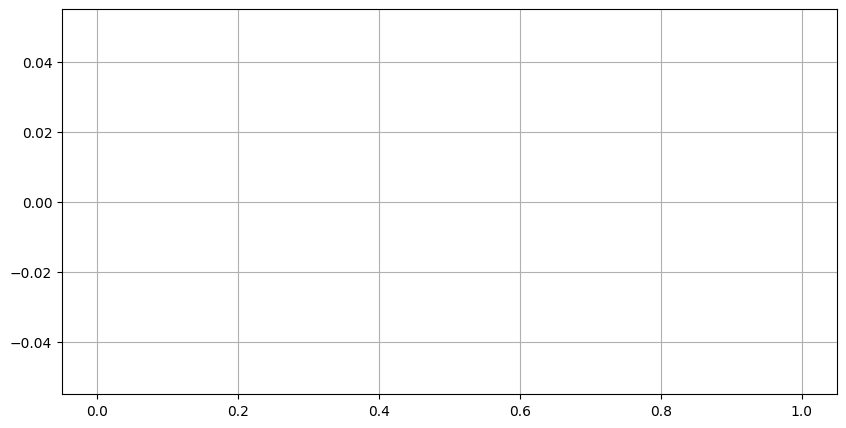

In [26]:
df['level'].hist(figsize = (10, 5))

In [28]:
df.pivot_table(index='level', aggfunc=len)

""
level


This is a function to oversample the dataset (so some of the images of levels 1-4 are present multiple times in the dataset):

In [29]:
def balance_data(class_size,df):
    train_df = df.groupby(['level']).apply(lambda x: x.sample(class_size, replace = True)).reset_index(drop = True)
    train_df = train_df.sample(frac=1).reset_index(drop=True)
    print('New Data Size:', train_df.shape[0], 'Old Size:', df.shape[0])
    train_df['level'].hist(figsize = (10, 5))
    return train_df

In [32]:
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(df,test_size=0.2) # Here we will perform an 80%/20% split of the dataset, with stratification to keep similar distribution in validation set

7022

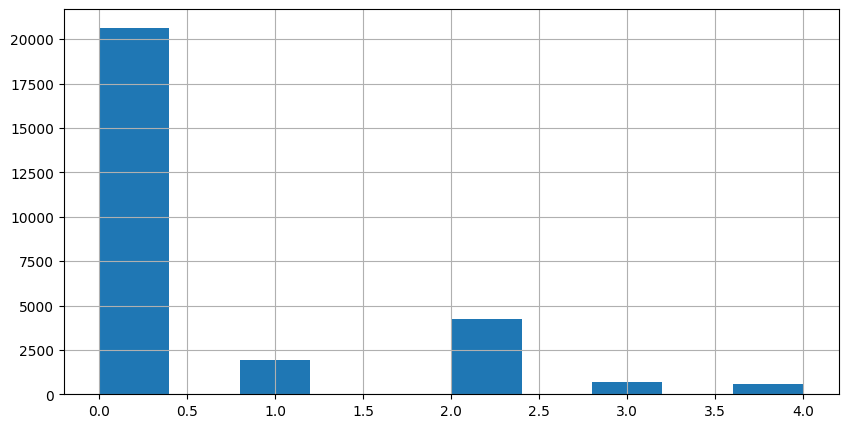

In [33]:
train_df['level'].hist(figsize = (10, 5))
len(val_df)

In [34]:
train_df.pivot_table(index='level', aggfunc=len)

,path
level,
0,20655
1,1934
2,4242
3,693
4,562


New Data Size: 103275 Old Size: 28086


/tmp/ipykernel_3255/1629605652.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_df = df.groupby(['level']).apply(lambda x: x.sample(class_size, replace = True)).reset_index(drop = True)


<Axes: >

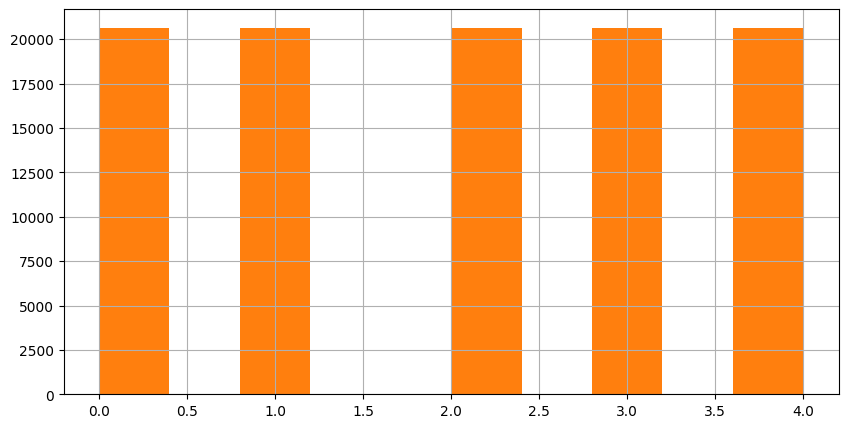

In [35]:
train_df = balance_data(train_df.pivot_table(index='level', aggfunc=len).max().max(),train_df) # I will oversample such that all classes have the same number of images as the maximum
train_df['level'].hist(figsize = (10, 5))

In [36]:
df = pd.concat([train_df,val_df]) #beginning of this dataframe is the oversampled training set, end is the validation set
len(df)

110297

In [37]:
from PIL import Image

im = Image.open(train_df['path'][1])
width, height = im.size
print(width,height)

1024 810


The images are actually quite big. We will resize to a much smaller size and try to use progressive resizing to our advantage when dealing with such a small dataset.

In [38]:
bs = 16 #smaller batch size is better for training, but may take longer
sz=224

Here, I load the dataset into the `ImageItemList` class provided by `fastai`. The fastai library also implements various transforms for data augmentation to improve training. While there are some defaults that I leave intact, I add vertical flipping (`do_flip=True`) and 360 deg. `max_rotate=360` as those have been commonly used for this particular problem.

Typically, one would use the `ImageDataBunch` class to load the dataset much easier, but since I needed to do some custom tasks for splitting and oversampling, I have to use this customized creation of the DataBunch.

In [60]:
import collections
import collections.abc
import torch
import fastai.vision.image

# Patch fastai's affine function to prevent float32 vs float64 (double) mismatch
_old_affine = fastai.vision.image.Image.affine
def _patched_affine(self, func, *args, **kwargs):
    m = tensor(func(*args, **kwargs)).to(self.device)
    # Force the transformation matrix to match the image's float precision
    if self.affine_mat.dtype != m.dtype:
        m = m.to(self.affine_mat.dtype)
    self.affine_mat = self.affine_mat @ m
    return self
fastai.vision.image.Image.affine = _patched_affine

# Adding patch for compatibility with fastai v1 under Python 3.10+
collections.Sized = collections.abc.Sized

# Keep the leading slash for absolute paths
df['path'] = df['path'].astype(str).apply(lambda p: '/' + p.lstrip('/'))

tfms = get_transforms(do_flip=True,flip_vert=True,max_rotate=360,max_warp=0,max_zoom=1.1,max_lighting=0.1,p_lighting=0.5)
src = (ImageItemList.from_df(df=df,path='/',cols='path')
        .split_by_idx(range(len(train_df)-1,len(df)))
        .label_from_df(cols='level')
      )
data= (src.transform(tfms,size=sz)
        .databunch(bs=bs,num_workers=0)
        .normalize(imagenet_stats)
       )

/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  return F.grid_sample(x[None], coords, mode=mode, padding_mode=padding_mode)[0]
/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  return F.grid_sample(x[None], coords, mode=mode, padding_mode=padding_mode)[0]
/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentat

/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  return F.grid_sample(x[None], coords, mode=mode, padding_mode=padding_mode)[0]
/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  return F.grid_sample(x[None], coords, mode=mode, padding_mode=padding_mode)[0]
/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentat

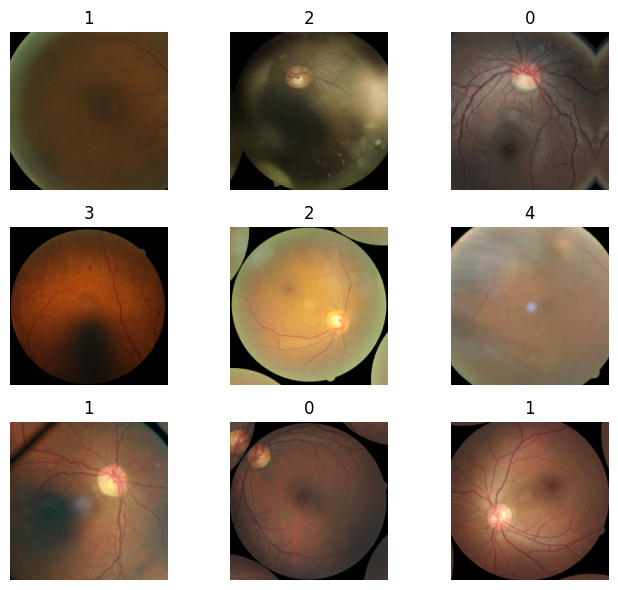

In [58]:
# EXPLANATION OF THE ERROR:
# 1. Double path prefixing: When `path='/'` or `path='.'` was combined with absolute paths, fastai resolved them as `././/root/...` which is invalid.
# 2. NumPy String Wrapping: Pandas often wraps string objects as `np.str_` type. When fastai evaluates paths using repr() internally, it parses them literally as `np.str_('/root/...')` which breaks standard os.open.
#
# SOLUTION: Force the paths to be standard native python string types and keep absolute references.

# Clean the paths of any numpy string wrappers and force standard python string objects
df['path'] = df['path'].apply(lambda x: str(x))

# Safely display a batch of data
data.show_batch(rows=3, figsize=(7,6))

We can see that because of the center cropping and data augmentation, some of the images are cut off or have weird artifacts. This is probably because the fundus image was not 100% centered in the original data. For now, I will ignore these problems.

In [54]:
print(data.classes)
len(data.classes),data.c

[0, 1, 2, 3, 4]


(5, 5)

# Training (Transfer learning)

The Kaggle competition used the Cohen's quadratically weighted kappa so I have that here to compare. This is a better metric when dealing with imbalanced datasets like this one, and for measuring inter-rater agreement for categorical classification (the raters being the human-labeled dataset and the neural network predictions). Here is an implementation based on the scikit-learn's implementation, but converted to a pytorch tensor, as that is what fastai uses.

In [55]:
from sklearn.metrics import cohen_kappa_score
def quadratic_kappa(y_hat, y):
    return torch.tensor(cohen_kappa_score(torch.argmax(y_hat,1), y, weights='quadratic'),device='cuda:0')

**Training:**

We use transfer learning, where we retrain the last layers of a pretrained neural network. I use the ResNet50 architecture trained on the ImageNet dataset, which has been commonly used for pre-training applications in computer vision. Fastai makes it quite simple to create a model and train:

In [56]:
import torchvision
learn = create_cnn(data, models.resnet50, metrics = [accuracy,quadratic_kappa])

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:135: UserWarning: Using 'weights' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


We use the learning-rate finder developed by Dr. Leslie Smith and implemented by the fastai team in their library:

In [ ]:
learn.lr_find()
learn.recorder.plot()

In [ ]:
learn.lr_find()

epoch,train_loss,valid_loss,accuracy,quadratic_kappa


/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  return F.grid_sample(x[None], coords, mode=mode, padding_mode=padding_mode)[0]
/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  return F.grid_sample(x[None], coords, mode=mode, padding_mode=padding_mode)[0]
/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentat

epoch,train_loss,valid_loss,accuracy,quadratic_kappa


/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  return F.grid_sample(x[None], coords, mode=mode, padding_mode=padding_mode)[0]
/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  return F.grid_sample(x[None], coords, mode=mode, padding_mode=padding_mode)[0]
/usr/local/lib/python3.13/dist-packages/fastai/vision/image.py:523: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentat

In [ ]:
learn.recorder.plot()

Here we can see that the loss decreases fastest around `lr=2e-3` so that is what we will use to train:

In [ ]:
learn.fit_one_cycle(4,max_lr = 2e-3)

In [ ]:
learn.recorder.plot_losses()

In [ ]:
learn.save('stage-1-224')

The previous model only trained the last model. We can unfreeze the rest of the model, and train the rest of the model using discriminative learning rates. The first layers aren't changed as much, with lower learning rates, while the last layers are changed more, with higher learning rates. We use the learning rate finder again, and use a range of learning rates for different layers in the neural network.

In [ ]:
learn.unfreeze()

In [ ]:
learn.lr_find()

In [ ]:
learn.recorder.plot()

In [ ]:
learn.fit_one_cycle(4, max_lr=slice(1e-6,1e-4))

In [ ]:
learn.recorder.plot_losses()

In [ ]:
learn.save('stage-2-224')

# Progressive resizing

Progressive resizing is a technique developed by Jeremy Howard as part of the fast.ai class and for the [DAWNBench challenge](https://www.fast.ai/2018/08/10/fastai-diu-imagenet/). The idea is that we train with smaller images at the beginning, and retrain with larger images, which will have more information to learn from. This could be very helpful for dealing with small datasets, and I decided to give this a try. I only resize once due to kernel time limitations, but theoretically, we could continue to resize and see if that improves accuracy, especially since the retinal images are so big in size.

In [ ]:
data = (src.transform(tfms,size=sz*2) #Data augmentation
        .databunch(bs=bs,num_workers=0) #DataBunch
        .normalize(imagenet_stats) #Normalize
       )

In [ ]:
learn.data = data
data.train_ds[0][0].shape

In [ ]:
learn.freeze()

In [ ]:
learn.lr_find()
learn.recorder.plot()

In [ ]:
learn.fit_one_cycle(4,max_lr=1e-3)

In [ ]:
learn.recorder.plot_losses()

In [ ]:
learn.save('stage-1-448')

In [ ]:
learn.unfreeze()

In [ ]:
learn.lr_find()
learn.recorder.plot()

In [ ]:
learn.fit_one_cycle(4,max_lr=slice(1e-6,1e-4))

In [ ]:
learn.recorder.plot_losses()

In [ ]:
learn.save('stage-2-448')

# Checking results

We look at our predictions and make a confusion matrix.

In [ ]:
interp = ClassificationInterpretation.from_learner(learn)

losses,idxs = interp.top_losses()

len(data.valid_ds)==len(losses)==len(idxs)

In [ ]:
interp.plot_top_losses(9, figsize=(15,11))

In [ ]:
interp.plot_confusion_matrix(figsize=(12,12), dpi=60)

Quite impressively, with only 1000 images, oversampling, and transfer learning, we acheive decent agreement with the correct labels!

# Future work:
There are other methods for dealing with imbalanced datasets. The most common alternative is to use a **weighted loss function**, with the class weights dependent on the distribution of the dataset.

Some possible future experiments include:
1. Training the dataset without the healthy (0) class, then retrain with the healthy class.
2. Possibly using [mixup](https://forums.fast.ai/t/mixup-data-augmentation/22764) as a form of data augmentation. It would be interesting to see how well it would perform with medical data.
3. Utilize [rectangular images](https://www.fast.ai/2018/08/10/fastai-diu-imagenet/) instead of cropping. Most of the data has an aspect ratio of ~1.5, and by default, the `fastai` library center-crops squares to pass into the network. Note for this dataset, it may not provide significant advantage as the circular retinal images are already padded, and cropping them removes much of the padding.

# Acknowledgements
Thanks to the `fastai` library and [fast.ai course](https://course.fast.ai/). The techniques used here were based mainly on lesson 1 and lesson 3 of the course.